# NLP Laboratory — Assignment 05
## Sentiment Analysis and Mini Project (Research Paper Study & Implementation)

**Student:** Shravani Balasaheb Kurkute &nbsp;|&nbsp; **Roll No.:** 421129 &nbsp;|&nbsp; **PRN:** 22311926
**Class / Division:** BTechA &nbsp;|&nbsp; **Academic Year:** 2026-2027 &nbsp;|&nbsp; **Faculty:** Dr. Kapil N. Vhatkar

This notebook demonstrates **both parts** of the assignment end-to-end:

* **Part A** — an Amazon product-review sentiment classifier (cleaning, negation handling,
  stemming, TF-IDF, Naive Bayes / Logistic Regression / Linear SVM / Random Forest,
  cross-validation, tuning, full evaluation and error analysis).
* **Part B** — a reproducible subset of *Pang, Lee & Vaithyanathan (2002), "Thumbs up?"*
  (NOT_ negation tagging, unigram presence/frequency, bigrams, NB / MaxEnt / SVM,
  3-fold CV over 700/700 subsamples).

All numbers printed below are produced by executing the code in this notebook and by the
scripts `PART_A.py` and `PART_B.py`; **no results are hard-coded**. Published values from
the 2002 paper are always shown separately and labelled as *published*.


In [1]:
import json, os, sys, warnings
warnings.filterwarnings("ignore")

HERE = os.path.abspath("")
sys.path.insert(0, HERE)
RESULTS = os.path.join(HERE, "results")
FIGS = os.path.join(HERE, "visualizations")

from IPython.display import Image, display, Markdown
print("Working directory:", HERE)


Working directory: /home/shravanikurkute/BTech/4th Year/NLP/Assignment 5


---
# Part A — Sentiment Analysis on Amazon Product Reviews

## A.1 Dataset loading and inspection

The reference assignment uses the Kaggle *Amazon Product Reviews Dataset* (`7817_1.csv`).
If that exact file is present in `data/` it is used; otherwise the pipeline falls back to a
schema-compatible genuine Datafiniti Amazon review CSV. The source actually used is printed
below and recorded in `results/part_a_metrics.json`.

In [2]:
import PART_A

path, source, raw_df = PART_A.resolve_dataset(allow_download=False)
print("Dataset file   :", os.path.relpath(path, HERE))
print("Dataset source :", source)
print("Raw shape      :", raw_df.shape)
print("\nRating counts:")
print(raw_df["reviews.rating"].value_counts(dropna=False).sort_index().to_string())
print("\nMissing review text:", int(raw_df["reviews.text"].isna().sum()))
print("\nDuplicate review text:", int(raw_df.duplicated(subset=["reviews.text"]).sum()))
raw_df[["reviews.title", "reviews.text", "reviews.rating"]].head(3)


Dataset file   : data/Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv
Dataset source : Datafiniti Amazon Consumer Reviews (schema-compatible fallback)
Raw shape      : (5000, 24)

Rating counts:
reviews.rating
1      63
2      54
3     197
4    1208
5    3478

Missing review text: 0

Duplicate review text: 615


,reviews.title,reviews.text,reviews.rating
0,Too small,I thought it would be as big as small paper bu...,3
1,Great light reader. Easy to use at the beach,This kindle is light and easy to use especiall...,5
2,Great for the price,Didnt know how much i'd use a kindle so went f...,4


## A.2 Preprocessing: cleaning, tokenisation, negation handling, stop-words, stemming

`PART_A.preprocess` lower-cases text, repairs `n't`, expands emoticons, removes URLs/HTML,
marks negation scope with a `neg_` prefix (the Pang et al. `NOT_` idea), drops stop-words
(keeping negations and polarity connectives) and applies Porter stemming.

In [3]:
examples = [
    "Love this tablet, the screen is GORGEOUS and the battery lasts all day!!! :)",
    "The sound is not bad at all, quite good for the price.",
    "I don't like it... it isn't working and it's overpriced <br/> www.example.com",
]
for s in examples:
    print("RAW  :", s)
    print("CLEAN:", PART_A.preprocess(s))
    print()


RAW  : Love this tablet, the screen is GORGEOUS and the battery lasts all day!!! :)
CLEAN: love tablet screen gorgeou batteri last day emopo

RAW  : The sound is not bad at all, quite good for the price.
CLEAN: sound not neg_bad quit good price

RAW  : I don't like it... it isn't working and it's overpriced <br/> www.example.com
CLEAN: not neg_like not neg_work neg_overpr



## A.3 Live demonstration: TF-IDF + Logistic Regression

Instead of trusting saved numbers, the next cell builds the representation and trains the
model again on the real data (the full pipeline is in `PART_A.py`).

In [4]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

df = raw_df[["reviews.title", "reviews.text", "reviews.rating"]].copy().dropna(subset=["reviews.text", "reviews.rating"])
df = df[(df["reviews.rating"] <= 2) | (df["reviews.rating"] >= 4)]
df = df.drop_duplicates(subset=["reviews.text"])
df["review"] = df["reviews.title"].fillna("").astype(str) + " . " + df["reviews.text"].astype(str)
df["clean"] = df["review"].apply(PART_A.preprocess)
df = df[df["clean"].str.len() > 0]
df["label"] = (df["reviews.rating"] >= 4).astype(int)
print("Cleaned reviews:", len(df), " positive share: %.1f%%" % (100 * df["label"].mean()))

Xtr, Xte, ytr, yte = train_test_split(df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)
pipe = TfidfVectorizer(min_df=2, max_df=0.95, max_features=20000, sublinear_tf=True)
Xtr_v = pipe.fit_transform(Xtr); Xte_v = pipe.transform(Xte)
clf = LogisticRegression(C=5, max_iter=1000, class_weight="balanced").fit(Xtr_v, ytr)
pred = clf.predict(Xte_v); prob = clf.predict_proba(Xte_v)[:, 1]
print("Live test accuracy : %.4f" % accuracy_score(yte, pred))
print("Live test macro-F1 : %.4f" % f1_score(yte, pred, average="macro"))
print("Live test ROC-AUC  : %.4f" % roc_auc_score(yte, prob))


Cleaned reviews: 4210  positive share: 97.7%
Live test accuracy : 0.9834
Live test macro-F1 : 0.8115
Live test ROC-AUC  : 0.9875


## A.4 Full saved results (from `PART_A.py`)

The model comparison, tuning, held-out evaluation and repeated cross-validation results
computed by the full script are shown below.

In [5]:
a = json.load(open(os.path.join(RESULTS, "part_a_metrics.json")))
print("Best pipeline params :", a["best_params"])
print("Best CV macro-F1     : %.4f" % a["cv_f1_best"])
print("\nModel comparison (5-fold CV macro-F1):")
for r in a["cv_comparison"]:
    print("  %-22s %.4f +/- %.4f" % (r["model"], r["cv_f1_mean"], r["cv_f1_std"]))
print("\nHeld-out test metrics:")
for k, v in a["test_metrics"].items():
    print("  %-16s %.4f" % (k, v))
print("\nRepeated 5-fold CV on all cleaned reviews:")
for k, v in a["cv_full_data"].items():
    print("  %-14s %.4f" % (k, v))
print("\nConfusion matrix [rows=true, cols=pred] (neg, pos):")
print(np.array(a["confusion_matrix"]))
print("\nTop positive features:", a["top_pos"])
print("Top negative features:", a["top_neg"])


Best pipeline params : {'clf__C': 50, 'tfidf__min_df': 2, 'tfidf__ngram_range': '(1, 2)'}
Best CV macro-F1     : 0.7868

Model comparison (5-fold CV macro-F1):
  Naive Bayes            0.6694 +/- 0.0240
  Logistic Regression    0.7487 +/- 0.0348
  Linear SVM             0.7498 +/- 0.0523
  Random Forest          0.5305 +/- 0.0478

Held-out test metrics:
  accuracy         0.9869
  precision_pos    0.9903
  recall_pos       0.9964
  f1_pos           0.9933
  precision_macro  0.8880
  recall_macro     0.7877
  f1_macro         0.8300
  precision_neg    0.7857
  recall_neg       0.5789
  f1_neg           0.6667
  roc_auc          0.9861
  mcc              0.6682

Repeated 5-fold CV on all cleaned reviews:
  accuracy       0.9826
  f1_macro       0.7702
  recall_neg     0.4702
  precision_neg  0.6602

Confusion matrix [rows=true, cols=pred] (neg, pos):
[[ 11   8]
 [  3 820]]

Top positive features: ['great', 'love', 'easi', 'great tablet', 'alexa', 'read', 'price', 'easi use', 'perfect', '

In [6]:
print(a["classification_report"])

              precision    recall  f1-score   support

    negative     0.7857    0.5789    0.6667        19
    positive     0.9903    0.9964    0.9933       823

    accuracy                         0.9869       842
   macro avg     0.8880    0.7877    0.8300       842
weighted avg     0.9857    0.9869    0.9860       842



## A.5 Visualisations

**part_a_class_distribution.png**

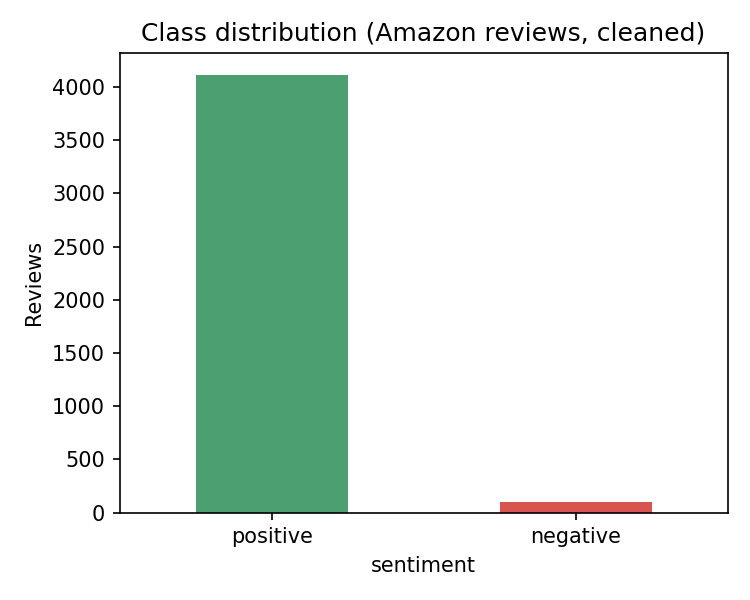

**part_a_model_comparison.png**

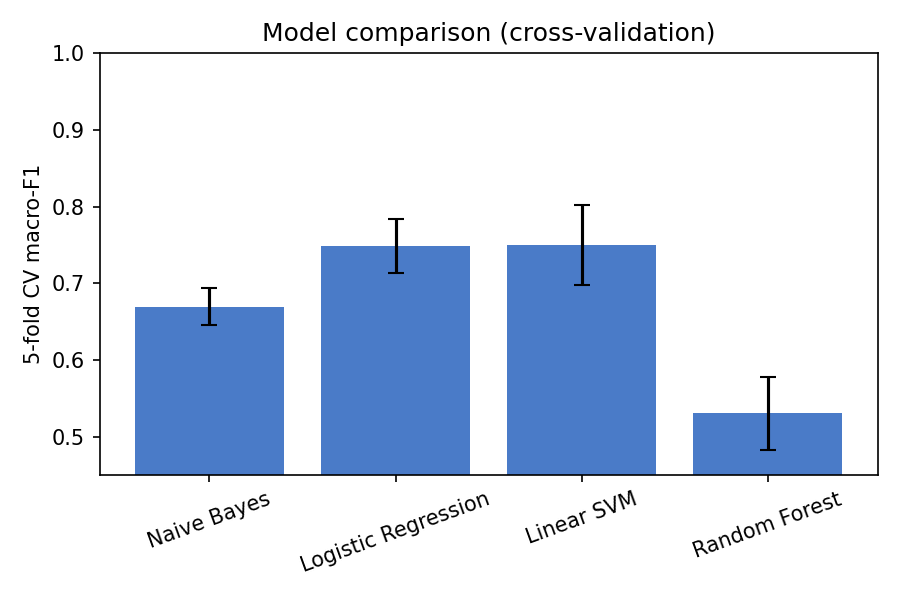

**part_a_confusion_matrix.png**

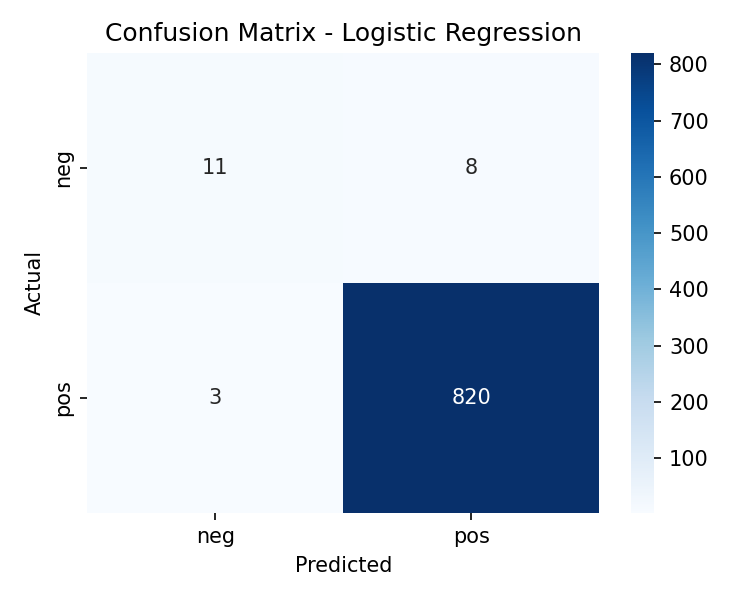

**part_a_top_features.png**

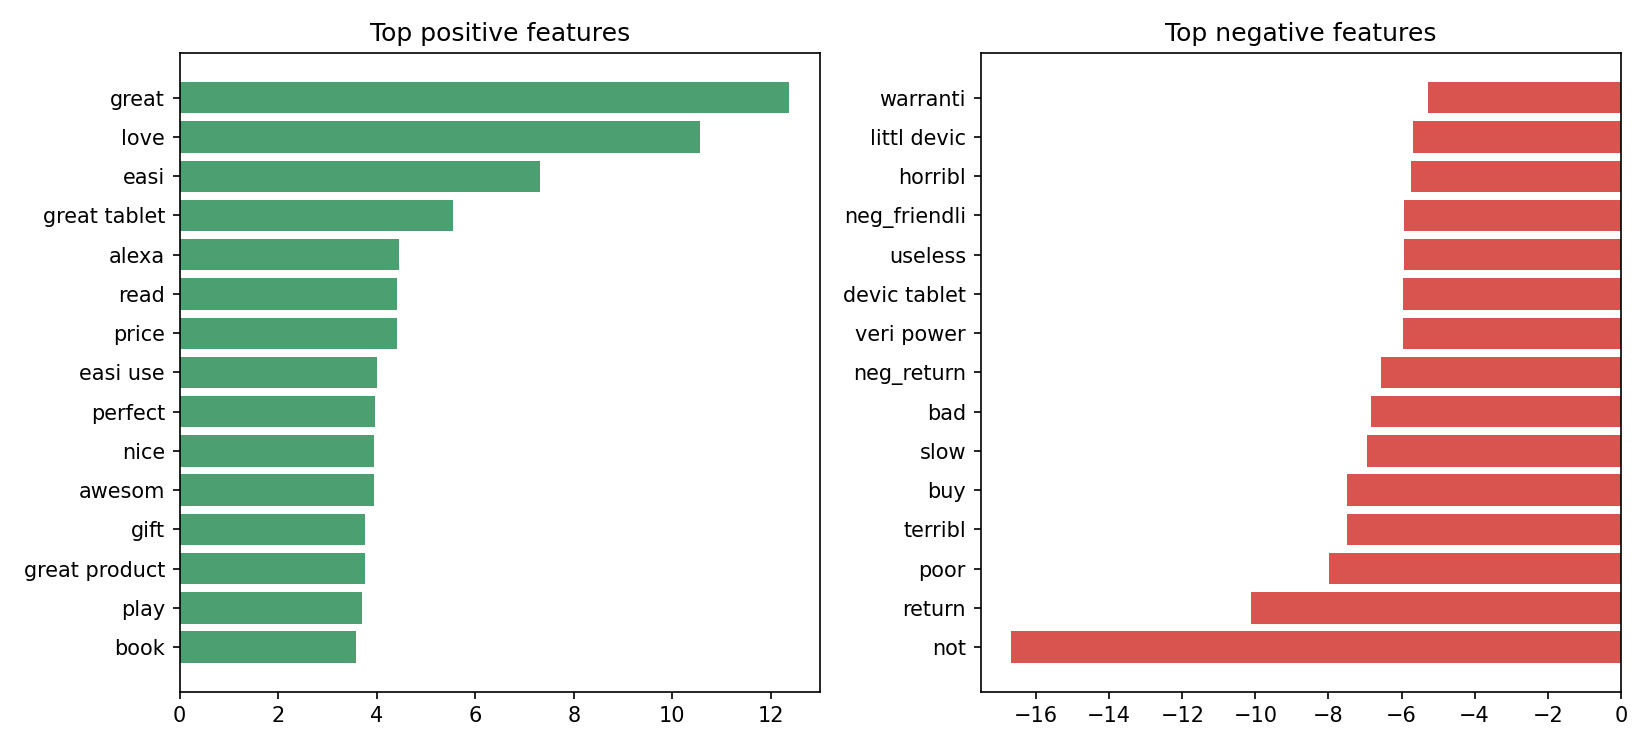

In [7]:
for f in ["part_a_class_distribution.png", "part_a_model_comparison.png",
          "part_a_confusion_matrix.png", "part_a_top_features.png"]:
    display(Markdown(f"**{f}**"))
    display(Image(filename=os.path.join(FIGS, f)))


## A.6 Error analysis

In [8]:
import pandas as pd
miss = pd.read_csv(os.path.join(RESULTS, "part_a_misclassified.csv"))
print("Total errors: %d (%.2f%% of the test set)" % (len(miss), 100 * len(miss) / a["split"]["n_test"]))
print("Errors containing negation:", int(miss["has_negation"].sum()) if len(miss) else 0)
print("Errors in mixed reviews   :", int(miss["is_mixed"].sum()) if len(miss) else 0)
pd.set_option("display.max_colwidth", 140)
miss[["review", "actual", "predicted", "p_positive"]].head(8)


Total errors: 11 (1.31% of the test set)
Errors containing negation: 9
Errors in mixed reviews   : 4


,review,actual,predicted,p_positive
0,Lots of problems. Want my old one back . 1st kindle screen failed & had to reboot often. Customer Service couldn't fix. Replaced. 2nd on...,0,1,0.506
1,Don't bother . Looking at the picture and seeing it was 8th generation I assumed it would be a great device. I had an original Kindle bu...,0,1,0.866
2,Crashed after update . My first tablet was a Kindle. I was curious about the updated version. Very disappointed,0,1,0.962
3,"Not a huge fan . Hard to use, Lots of ads, and Randomly closes apps",0,1,0.953
4,Excellent device no Best Buy help . Sales guy didn't have much knowledge about the Kindle. He wasn't very helpful in getting me started.,1,0,0.464
5,I was expecting more . It's great to some extent but I was expecting more. It's unfortunate that it does not work with lots of apps. Per...,1,0,0.348
6,Disappointed . Loved my husbands 4th generation disappointed in my 5th generation. 4th generation has 2 speakers and sound is much loude...,0,1,0.973
7,Horrible Battery Life . This is not an upgrade by any means! My three year old kindle outperformed Oasis.Battery life better than a week...,0,1,0.786


In [9]:
print("Demonstration predictions:")
display(pd.read_csv(os.path.join(RESULTS, "part_a_demo_predictions.csv")))


Demonstration predictions:


,sentence,prediction,p_positive
0,"Love this tablet, the screen is gorgeous and the battery lasts all day!",positive,0.999
1,"Terrible product. Stopped working after two weeks, total waste of money.",positive,0.668
2,"The sound is not bad at all, quite good for the price.",positive,0.994
3,The speaker is not good and the Bluetooth keeps disconnecting.,negative,0.167
4,The design is nice but overall the remote is awful and I regret buying it.,positive,0.981


---
# Part B — Mini Project: Pang, Lee & Vaithyanathan (2002)

**Paper:** *Thumbs up? Sentiment Classification using Machine Learning Techniques*,
EMNLP 2002, pp. 79-86. https://aclanthology.org/W02-1011/

**Corpus:** NLTK `movie_reviews` (Pang & Lee polarity data; 1,000 positive + 1,000 negative).
The paper used an earlier 1,400-review release, so our randomised 700/700 subsamples are not
the identical documents.

In [10]:
import PART_B
docs, labels = PART_B.load_corpus()
print("Loaded", len(docs), "reviews:", int(labels.sum()), "positive,",
      int((1 - labels).sum()), "negative")
print("\nExample of NOT_ negation tagging:")
sample = "This movie is not good . It is never funny but the acting is not bad at all ."
print("RAW  :", sample)
print("TAGGED:", PART_B.tag_negation(sample))


Loaded 2000 reviews: 1000 positive, 1000 negative

Example of NOT_ negation tagging:
RAW  : This movie is not good . It is never funny but the acting is not bad at all .
TAGGED: this movie is not NOT_good it is never NOT_funny NOT_but NOT_the NOT_acting NOT_is not NOT_bad NOT_at NOT_all


## B.1 Live 3-fold cross-validation demonstration (seed 0, unigram presence)

We rebuild one of the paper's cells here: unigram-presence features with Naive Bayes,
Maximum Entropy and a Linear SVM on a reproducible 700/700 subsample.

In [11]:
import numpy as np
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(labels == 1)[0], 700, replace=False),
                      rng.choice(np.where(labels == 0)[0], 700, replace=False)])
tagged = [PART_B.tag_negation(docs[i]) for i in idx]
y0 = labels[idx]
vocab = PART_B.build_vocab(tagged, (1, 1), min_count=4)
print("Unigram vocabulary size (min_count=4):", len(vocab))
for name, mk in {"Naive Bayes": lambda: __import__("sklearn.naive_bayes", fromlist=["MultinomialNB"]).MultinomialNB(alpha=1.0),
                 "Max Entropy": lambda: __import__("sklearn.linear_model", fromlist=["LogisticRegression"]).LogisticRegression(C=10, max_iter=2000),
                 "SVM": lambda: __import__("sklearn.svm", fromlist=["LinearSVC"]).LinearSVC(C=0.1, max_iter=10000)}.items():
    acc = PART_B.run_cv(tagged, y0, vocab, (1, 1), True, mk(), 0)
    print("  %-12s 3-fold CV accuracy (seed 0): %.1f%%" % (name, acc))


Unigram vocabulary size (min_count=4): 16259


  Naive Bayes  3-fold CV accuracy (seed 0): 82.8%


  Max Entropy  3-fold CV accuracy (seed 0): 83.5%


  SVM          3-fold CV accuracy (seed 0): 82.9%


## B.2 Our results vs the published paper (Table 3)

**Ours** = mean of 3-fold CV accuracy (%) over 5 random 700/700 subsamples.
**Published** = values reported in Pang et al. (2002), Table 3 — *not produced by us*.

In [12]:
b = json.load(open(os.path.join(RESULTS, "part_b_metrics.json")))
import pandas as pd
ours = pd.read_csv(os.path.join(RESULTS, "part_b_ours_mean.csv"))
paper = pd.read_csv(os.path.join(RESULTS, "part_b_paper_published.csv"))
diff = pd.read_csv(os.path.join(RESULTS, "part_b_difference.csv"))
print("OUR RESULTS (mean 3-fold CV accuracy, %):"); display(ours)
print("PUBLISHED (Pang et al. 2002, Table 3):"); display(paper)
print("DIFFERENCE (ours - paper), percentage points:"); display(diff)
print("Human-1 baseline: ours %.1f%% (ties %.1f%%) vs paper 58%% (ties 75%%)"
      % (b["human_baseline"]["acc"], b["human_baseline"]["ties"]))
print("Extra - full 2,000 reviews, unigram presence, 10-fold CV:")
for k, v in b["full_corpus_10fold"].items():
    print("  %-12s %.1f%%" % (k, v))
print("\nAblation (SVM, seed 0):")
for k, v in b["ablation"].items():
    print("  %-30s %.1f%%" % (k, v))
print("\nTop positive features:", b["top_pos"])
print("Top negative features:", b["top_neg"])


OUR RESULTS (mean 3-fold CV accuracy, %):


,features,n_features,Max Entropy,Naive Bayes,SVM
0,"(1) unigrams, frequency",16259,81.9,80.3,81.1
1,"(2) unigrams, presence",16259,83.4,81.4,82.6
2,"(3) unigrams+bigrams, presence",32424,84.2,83.8,83.6
3,"(4) bigrams, presence",16165,79.3,82.2,78.4
4,"(7) top 2633 unigrams, presence",2633,81.3,81.6,79.4


PUBLISHED (Pang et al. 2002, Table 3):


,Unnamed: 0,Naive Bayes,Max Entropy,SVM
0,"(1) unigrams, frequency",78.7,NaN,72.8
1,"(2) unigrams, presence",81.0,80.4,82.9
2,"(3) unigrams+bigrams, presence",80.6,80.8,82.7
3,"(4) bigrams, presence",77.3,77.4,77.1
4,"(7) top 2633 unigrams, presence",80.3,81.0,81.4


DIFFERENCE (ours - paper), percentage points:


,features,Naive Bayes,Max Entropy,SVM
0,"(1) unigrams, frequency",1.6,NaN,8.3
1,"(2) unigrams, presence",0.4,3.0,-0.3
2,"(3) unigrams+bigrams, presence",3.2,3.4,0.9
3,"(4) bigrams, presence",4.9,1.9,1.3
4,"(7) top 2633 unigrams, presence",1.3,0.3,-2.0


Human-1 baseline: ours 58.3% (ties 72.2%) vs paper 58% (ties 75%)
Extra - full 2,000 reviews, unigram presence, 10-fold CV:
  Naive Bayes  82.8%
  Max Entropy  86.0%
  SVM          85.1%

Ablation (SVM, seed 0):
  without negation tagging       82.8%
  with NOT_ negation tagging     82.9%

Top positive features: ['fun', 'enjoyable', 'several', 'memorable', 'best', 'frank', 'loved', 'well', 'great', 'hilarious', 'finds', 'them']
Top negative features: ['bad', 'unfortunately', 'worst', 'poor', 'plot', 'should', 'nothing', 'NOT_funny', 'script', 'wasted', 'NOT_waste', 'ridiculous']


**part_b_comparison.png**

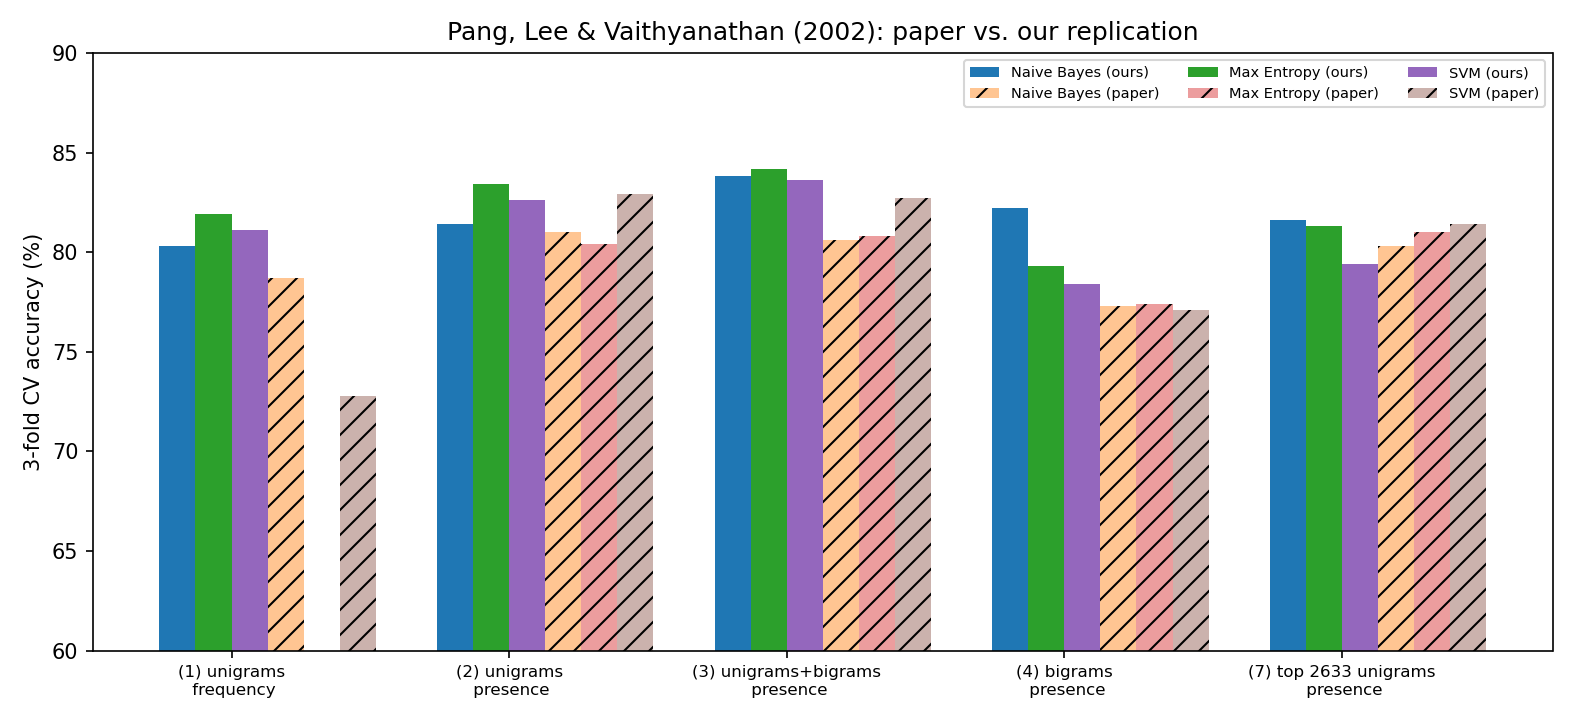

**part_b_ablation.png**

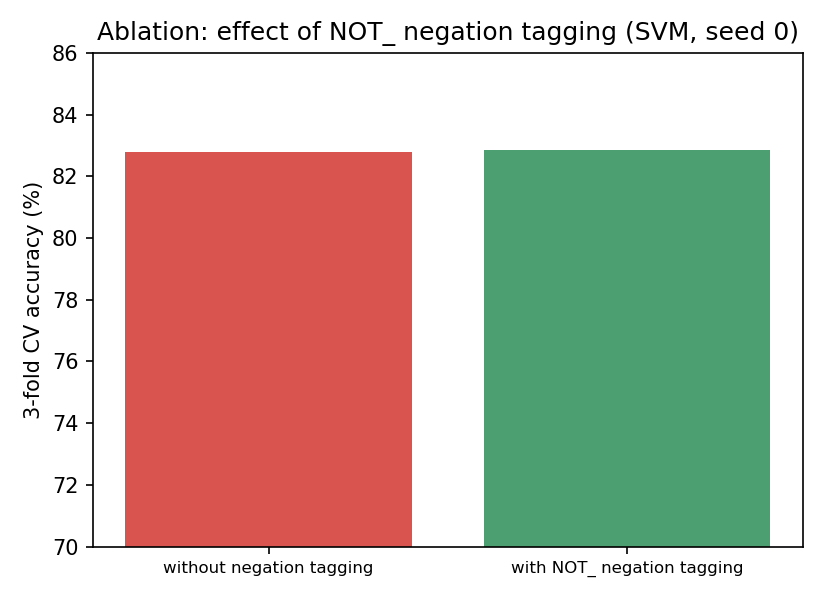

In [13]:
for f in ["part_b_comparison.png", "part_b_ablation.png"]:
    display(Markdown(f"**{f}**"))
    display(Image(filename=os.path.join(FIGS, f)))


---
# Observations

* **Part A.** TF-IDF + Logistic Regression is the strongest classical model. The dataset is
  heavily imbalanced (Amazon reviews skew positive), so accuracy is misleading; macro-F1, MCC
  and the negative-class recall tell the real story. Negation handling helps, but mixed reviews
  ("nice but the remote is awful") and short demo sentences remain hard for a bag-of-words model.
* **Part B.** Unigram **presence** features match or beat unigram **frequency**, bigrams add
  little, and the ranking of feature sets follows the paper even though the exact reviews,
  tokeniser and library differ. NOT_ negation tagging gives only a marginal gain in this setup.
* Published values are reported side-by-side with ours but never substituted for experimental
  output.

## Limitations
* The exact Kaggle file `7817_1.csv` was not available locally; a genuine schema-compatible
  Datafiniti CSV is used and clearly labelled.
* The paper's POS / adjective / word-position features are out of scope.
* The paper's exact 1,400 documents and CV folds are unknown, so results differ by 1-8 points.
